# 04 · Acceso por etapas e Hipótesis 2

**Proyecto semestral IMT2200, Grupo 5:** *¿Mide el NEM lo mismo para todos?*

**Entrada:** `data/processed/muestra.parquet`. Cómo se relaciona la brecha
condicional con postular, quedar seleccionado y matricularse, **a igual PAES**.
Todos los resultados son asociaciones, no efectos causales.

In [1]:
# Librerías, funciones del proyecto (src/) y carga de datos.
import sys

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf

sys.path.insert(0, '..')  # para importar src/ desde notebooks/
from src.funciones import mostrar, odds_ratios, preparar_datos  # noqa: E402

datos = preparar_datos(pd.read_parquet('../data/processed/muestra.parquet'))

## 1. Datos y etapas del acceso

Cada etapa se estudia entre quienes llegaron a la anterior: **postula** (toda la
muestra), **seleccionado | postuló** y **matriculado | seleccionado**.

**Modelo.** Una regresión logística por etapa según la brecha condicional, **a
igual PAES** (`PAES_z`), electiva, año, dependencia, decil, sexo y modalidad. Se
reporta el **odds ratio (OR)**: cuánto se multiplican las chances de pasar la etapa
por cada 1 DE más de brecha (OR > 1: más chances; OR < 1: menos). Los errores
estándar se agrupan por colegio, porque sus estudiantes no son independientes.

**Puntaje ponderado.** El NEM entra en el puntaje con que se selecciona, así que una
parte de la asociación es **mecánica**. Para separarla se controla por el puntaje
ponderado máximo (`ptje_ponderado_max`, en unidades de 100 puntos), que solo existe
para quienes tienen una postulación válida (en 2023 viene como 0 en el resto y se
trata como faltante).

In [2]:
# 1. Estudiantes de cada etapa y % que la pasa por tercil de PAES.
postulantes = datos[datos['postulo'] == 1]
seleccionados = datos[datos['seleccionado'] == 1]
ETAPAS = [('postula', 'postulo', datos),
          ('seleccionado | postuló', 'seleccionado', postulantes),
          ('matriculado | seleccionado', 'matriculado', seleccionados)]
tasas = {}
for nombre, variable, d in ETAPAS:
    print(f'{nombre}: {len(d)} estudiantes')
    tasas[nombre] = 100 * d.groupby('tercil_paes', observed=True)[
        variable].mean()
print('% que pasa cada etapa, por tercil de PAES:')
display(pd.DataFrame(tasas).round(1))

postula: 654142 estudiantes
seleccionado | postuló: 439519 estudiantes
matriculado | seleccionado: 359932 estudiantes
% que pasa cada etapa, por tercil de PAES:


,postula,seleccionado | postuló,matriculado | seleccionado
tercil_paes,,,
PAES baja,46.4,64.2,71.3
PAES media,68.2,81.3,76.9
PAES alta,87.0,91.8,83.9


## 2. Modelo logístico de cada etapa

Se muestran los OR de la brecha condicional, de la PAES, de cada dependencia
(respecto de Part. subvencionado) y del sexo.

In [3]:
# 2. Un modelo logístico por etapa, con errores agrupados por colegio.
CONTROLES = ('PAES_z + electiva + C(ANIO) + dependencia + decil + sexo'
             ' + modalidad')
tablas = {}
for nombre, variable, d in ETAPAS:
    resultado = smf.logit(f'{variable} ~ brecha_cond + {CONTROLES}', d).fit(
        disp=False, cov_type='cluster', cov_kwds={'groups': d['RBD']})
    tablas[nombre] = odds_ratios(resultado).filter(
        regex='brecha|PAES|dependencia|sexo', axis=0)
display(pd.concat(tablas).round(3))

odds_ratio  ic95_inf  \
postula                    dependencia[T.Adm. delegada]       0.917     0.804   
                           dependencia[T.Municipal]           0.915     0.877   
                           dependencia[T.Part. pagado]        1.236     1.170   
                           dependencia[T.SLEP]                0.926     0.863   
                           sexo[T.Mujer]                      1.457     1.430   
                           brecha_cond                        1.562     1.543   
                           PAES_z                             2.719     2.685   
seleccionado | postuló     dependencia[T.Adm. delegada]       1.105     0.985   
                           dependencia[T.Municipal]           0.938     0.894   
                           dependencia[T.Part. pagado]        1.025     0.974   
                           dependencia[T.SLEP]                0.902     0.850   
                           sexo[T.Mujer]                      0.629     0.615   
                           brecha_cond                        2.185     2.141   
                           PAES_z                             2.459     2.398   
matriculado | seleccionado dependencia[T.Adm. delegada]       0.954     0.881   
                           dependencia[T.Municipal]           1.093     1.042   
                           dependencia[T.Part. pagado]        1.007     0.940   
                           dependencia[T.SLEP]                1.266     1.189   
                           sexo[T.Mujer]                      0.755     0.737   
                           brecha_cond                        1.316     1.295   
                           PAES_z                             1.472     1.452   

                                                         ic95_sup  valor_p  
postula                    dependencia[T.Adm. delegada]     1.047    0.200  
                           dependencia[T.Municipal]         0.954    0.000  
                           dependencia[T.Part. pagado]      1.306    0.000  
                           dependencia[T.SLEP]              0.994    0.033  
                           sexo[T.Mujer]                    1.484    0.000  
                           brecha_cond                      1.581    0.000  
                           PAES_z                           2.753    0.000  
seleccionado | postuló     dependencia[T.Adm. delegada]     1.240    0.089  
                           dependencia[T.Municipal]         0.984    0.009  
                           dependencia[T.Part. pagado]      1.078    0.342  
                           dependencia[T.SLEP]              0.956    0.001  
                           sexo[T.Mujer]                    0.643    0.000  
                           brecha_cond                      2.229    0.000  
                           PAES_z                           2.520    0.000  
matriculado | seleccionado dependencia[T.Adm. delegada]     1.033    0.246  
                           dependencia[T.Municipal]         1.148    0.000  
                           dependencia[T.Part. pagado]      1.078    0.847  
                           dependencia[T.SLEP]              1.348    0.000  
                           sexo[T.Mujer]                    0.774    0.000  
                           brecha_cond                      1.337    0.000  
                           PAES_z                           1.493    0.000

**Interpretación** (todo a igual PAES, electiva, año, decil, sexo y modalidad):

- **Brecha condicional:** más brecha se asocia a más chances en las tres etapas.
  Cada 1 DE más de brecha multiplica las chances de postular por 1,56, de quedar
  seleccionado (entre quienes postulan) por 2,19 y de matricularse (entre los
  seleccionados) por 1,32.
- **Dependencia** (respecto de Part. subvencionado): los estudiantes de SLEP y de
  colegios municipales postulan algo menos (OR 0,93 y 0,92) y quedan seleccionados
  algo menos (0,90 y 0,94), pero **una vez seleccionados se matriculan más** (SLEP
  1,27; Municipal 1,09). Part. pagado postula más (1,24) y no se distingue en
  selección ni en matrícula.
- **Sexo:** las mujeres postulan más (OR 1,46), pero a igual PAES y brecha quedan
  seleccionadas menos (0,63) y se matriculan menos (0,76). Con estos datos no se
  puede saber por qué (por ejemplo, si postulan a carreras más selectivas); queda
  como tema a revisar.

## 3. Hipótesis 2: brecha y acceso con PAES baja

*En niveles de PAES baja, una mayor brecha condicional se asocia con una mayor
probabilidad de matrícula, incluso a igual puntaje ponderado.*

Se estima el OR de la brecha condicional en cada tercil de PAES y en cada etapa. En
las etapas 2 y 3 se estima dos veces **con los mismos estudiantes** (los que tienen
puntaje ponderado): sin y con control por el puntaje ponderado. Si el OR baja a 1 al
controlar, la asociación es mecánica; si se mantiene sobre 1, hay algo más. En la
etapa 1 (postular) no existe puntaje ponderado para quienes no postulan, así que no
se puede controlar.

In [4]:
# 3.a OR de la brecha por etapa y tercil de PAES, sin y con el puntaje
# ponderado (en las etapas 2 y 3, con los mismos estudiantes).
filas = []
for nombre, variable, d in ETAPAS:
    for tercil, sub in d.groupby('tercil_paes', observed=True):
        variantes = [('sin puntaje ponderado', '')]
        if nombre != 'postula':
            sub = sub.dropna(subset=['ptje_100'])
            variantes.append(('con puntaje ponderado', ' + ptje_100'))
        for variante, extra in variantes:
            formula = f'{variable} ~ brecha_cond + {CONTROLES}{extra}'
            resultado = smf.logit(formula, sub).fit(
                disp=False, cov_type='cluster',
                cov_kwds={'groups': sub['RBD']})
            fila = odds_ratios(resultado).loc['brecha_cond']
            filas.append([nombre, tercil, variante, len(sub),
                          fila['odds_ratio'], fila['ic95_inf'],
                          fila['ic95_sup'], fila['valor_p']])
h2 = pd.DataFrame(filas, columns=['etapa', 'tercil', 'variante', 'n',
                                  'odds_ratio', 'ic95_inf', 'ic95_sup',
                                  'valor_p'])
h2 = h2.set_index(['etapa', 'tercil', 'variante'])
display(h2.round(3))

n  \
etapa                      tercil     variante                        
postula                    PAES baja  sin puntaje ponderado  218104   
                           PAES media sin puntaje ponderado  217997   
                           PAES alta  sin puntaje ponderado  218041   
seleccionado | postuló     PAES baja  sin puntaje ponderado   88468   
                                      con puntaje ponderado   88468   
                           PAES media sin puntaje ponderado  144974   
                                      con puntaje ponderado  144974   
                           PAES alta  sin puntaje ponderado  189199   
                                      con puntaje ponderado  189199   
matriculado | seleccionado PAES baja  sin puntaje ponderado   64905   
                                      con puntaje ponderado   64905   
                           PAES media sin puntaje ponderado  120802   
                                      con puntaje ponderado  120802   
                           PAES alta  sin puntaje ponderado  174046   
                                      con puntaje ponderado  174046   

                                                             odds_ratio  \
etapa                      tercil     variante                            
postula                    PAES baja  sin puntaje ponderado       1.705   
                           PAES media sin puntaje ponderado       1.513   
                           PAES alta  sin puntaje ponderado       1.379   
seleccionado | postuló     PAES baja  sin puntaje ponderado       2.577   
                                      con puntaje ponderado       0.875   
                           PAES media sin puntaje ponderado       2.350   
                                      con puntaje ponderado       0.933   
                           PAES alta  sin puntaje ponderado       1.479   
                                      con puntaje ponderado       0.769   
matriculado | seleccionado PAES baja  sin puntaje ponderado       1.449   
                                      con puntaje ponderado       1.126   
                           PAES media sin puntaje ponderado       1.336   
                                      con puntaje ponderado       1.061   
                           PAES alta  sin puntaje ponderado       1.220   
                                      con puntaje ponderado       0.914   

                                                             ic95_inf  \
etapa                      tercil     variante                          
postula                    PAES baja  sin puntaje ponderado     1.679   
                           PAES media sin puntaje ponderado     1.491   
                           PAES alta  sin puntaje ponderado     1.352   
seleccionado | postuló     PAES baja  sin puntaje ponderado     2.505   
                                      con puntaje ponderado     0.801   
                           PAES media sin puntaje ponderado     2.289   
                                      con puntaje ponderado     0.871   
                           PAES alta  sin puntaje ponderado     1.436   
                                      con puntaje ponderado     0.722   
matriculado | seleccionado PAES baja  sin puntaje ponderado     1.414   
                                      con puntaje ponderado     1.085   
                           PAES media sin puntaje ponderado     1.308   
                                      con puntaje ponderado     1.026   
                           PAES alta  sin puntaje ponderado     1.190   
                                      con puntaje ponderado     0.875   

                                                             ic95_sup  valor_p  
etapa                      tercil     variante                                  
postula                    PAES baja  sin puntaje ponderado     1.731    0.000  
                           PAES media sin puntaje ponderado     1.535    0.000  
                

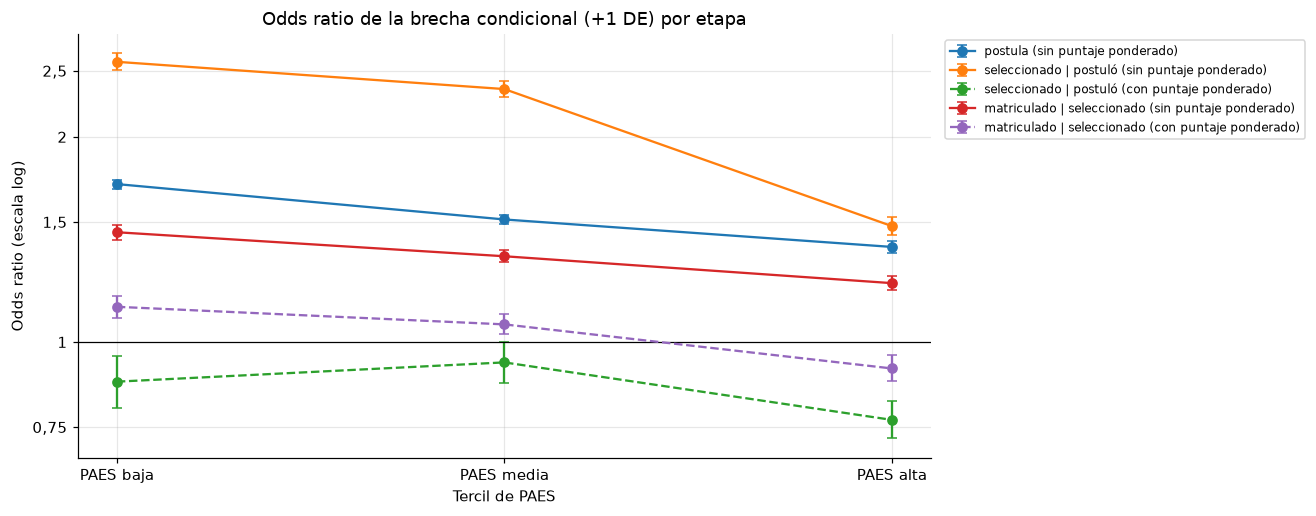

In [5]:
# 3.b OR de la brecha por tercil de PAES (escala logarítmica; la línea en 1
# indica "sin asociación").
fig, ax = plt.subplots(figsize=(10, 5))
for (etapa, variante), grupo in h2.groupby(level=['etapa', 'variante'],
                                           sort=False):
    grupo = grupo.droplevel(['etapa', 'variante'])
    error = [grupo['odds_ratio'] - grupo['ic95_inf'],
             grupo['ic95_sup'] - grupo['odds_ratio']]
    estilo = '--' if variante == 'con puntaje ponderado' else '-'
    ax.errorbar(grupo.index.astype(str), grupo['odds_ratio'], yerr=error,
                marker='o', capsize=3, linestyle=estilo,
                label=f'{etapa} ({variante})')
ax.axhline(1, color='black', linewidth=0.8)
ax.set_yscale('log')
ax.minorticks_off()
ax.set_yticks([0.75, 1, 1.5, 2, 2.5], ['0,75', '1', '1,5', '2', '2,5'])
ax.set(title='Odds ratio de la brecha condicional (+1 DE) por etapa',
       xlabel='Tercil de PAES', ylabel='Odds ratio (escala log)')
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
mostrar('acc_3b_or_brecha')

**Resultado de la Hipótesis 2:** se sostiene **solo en parte**.

- **Selección (etapa 2): la asociación es mecánica.** Con PAES baja, cada 1 DE más
  de brecha multiplica las chances de quedar seleccionado por 2,58, pero al
  controlar por el puntaje ponderado el OR cae a 0,88 (IC 95%: 0,80 a 0,96). Es
  decir, la brecha ayuda a quedar seleccionado porque el NEM sube el puntaje con que
  se postula; a igual puntaje ponderado no hay ventaja adicional.
- **Matrícula de los seleccionados (etapa 3): queda una asociación pequeña.** Con
  PAES baja el OR baja de 1,45 a **1,13 (IC 95%: 1,09 a 1,17)** al controlar por el
  puntaje ponderado: a igual PAES y a igual puntaje, los seleccionados con más brecha
  se matriculan algo más. Con PAES media el OR es 1,06 y con PAES alta es 0,91.
- **Postulación (etapa 1):** con PAES baja el OR es 1,71, pero aquí no se puede
  controlar por el puntaje ponderado, y una parte puede ser mecánica: para postular
  se exige un promedio de Lectora y M1 de al menos 458 puntos **o** estar en el 10%
  superior de notas del colegio, y el NEM ayuda a cumplir la segunda condición.

**En lenguaje simple:** con PAES baja, tener más NEM del esperado se asocia a llegar
más a la educación superior. La mayor parte de esa asociación ocurre porque el NEM
sube el puntaje de postulación (efecto mecánico). Lo que queda, a igual puntaje, es
una asociación pequeña en la decisión de matricularse. Es una asociación, no un
efecto causal.

## 4. Síntesis

- A igual PAES, más brecha condicional se asocia a más acceso en las tres etapas
  (OR 1,56 al postular, 2,19 al quedar seleccionado y 1,32 al matricularse).
- La ventaja en la **selección** es mecánica: desaparece al controlar por el puntaje
  ponderado.
- **Hipótesis 2 (en parte):** con PAES baja, los seleccionados con más brecha se
  matriculan más aun a igual puntaje ponderado (OR 1,13; IC 95%: 1,09 a 1,17).
- SLEP y Municipal postulan y quedan seleccionados algo menos que Part.
  subvencionado, pero sus seleccionados se matriculan más (SLEP OR 1,27). Las mujeres
  postulan más, pero quedan seleccionadas y se matriculan menos.
- **Decisión de método:** regresiones logísticas con errores agrupados por colegio,
  en vez de modelos logísticos mixtos, que en `statsmodels` son mucho más lentos y
  difíciles de explicar.